(evaluacion-e2)=
# 10.23. Resultados y evaluación estadística

Se comparan doce procedimientos con cinco semillas finales por procedimiento y dos referencias deterministas. Incluyen las cuatro familias de demanda/calendario, las arquitecturas numéricas ampliadas y dos formas de integrar texto oficial. El control N compartido por TaTS y fusión tardía se contabiliza una vez. TFT utiliza la configuración seleccionada del paquete; la alternativa compacta se conserva en el inventario. TGForecaster aporta arquitectura y pipeline, pero no resultados y queda fuera de las pruebas.

La evaluación cubre 1.461 orígenes diarios de 2022–2025 y 35.064 horas por semilla. La pérdida primaria es el promedio horario de error absoluto de cada origen, dividido por q168=215.617,90361589016 kWh. Primero se promedian las pérdidas de las cinco semillas; no se sustituye ese estimando por el error del pronóstico promedio.

$$L_{m,t}=\frac{1}{5\times24\times q_{168}}\sum_{s=1}^{5}\sum_{h=1}^{24}|y_{t,h}-\widehat y_{m,s,t,h}|.$$

El análisis es retrospectivo y compara procedimientos con entradas y presupuestos distintos. Los cuatro modelos base reciben demanda y calendario; las variantes ampliadas añaden clima, hidrología y precio. El repositorio usa 30 máscaras de ausencia y los paquetes usan tres por bloque. Los resultados no identifican un efecto puro de arquitectura. La incertidumbre temporal se estima mediante bootstrap circular pareado de 14 días y 10.000 réplicas, con sensibilidad de 7 y 28 días; condiciona las cinco inicializaciones ejecutadas.

La pauta E2 §§6.3 y 7.4 S7–S8 fundamenta las comparaciones y diagnósticos. Se conserva una familia global de 91 pares para cada contraste temporal, 66 pares de procedimientos con semillas para los contrastes entre ejecuciones y una familia específica exploratoria de dos contrastes textuales. Holm se aplica por tipo de prueba a la familia indicada; no se mezclan resultados crudos con ajustados.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'results/evaluacion_e2/protocolo.json').exists())
RESULT = ROOT/'results/evaluacion_e2'
protocolo = json.loads((RESULT/'protocolo.json').read_text(encoding='utf-8'))
benchmark = pd.read_csv(RESULT/'benchmark.csv')
nombres = dict(zip(benchmark.clave, benchmark.modelo))
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})


## Desempeño y precisión temporal

La figura muestra MASE e IC95 % temporal. Los intervalos se calculan sobre bloques de días compartidos por todos los procedimientos; las cinco semillas no se convierten en 5×1.461 observaciones independientes.

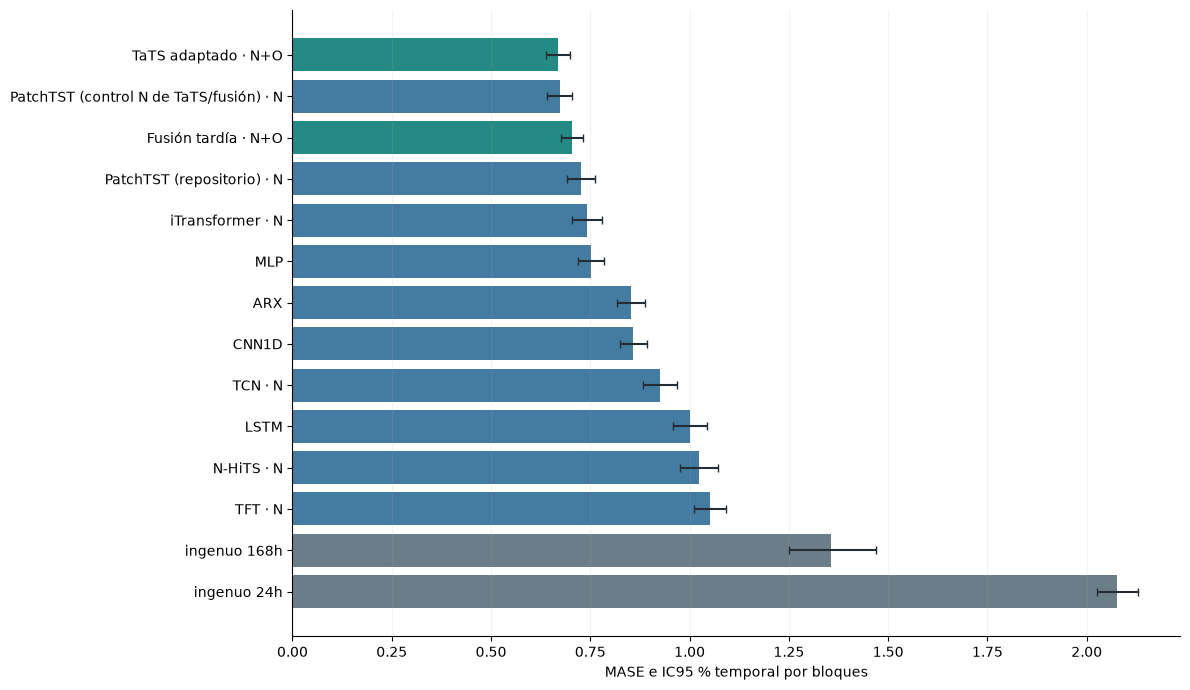

In [2]:
b = benchmark.sort_values('MASE',ascending=False)
fig, ax = plt.subplots(figsize=(12,7))
ypos = np.arange(len(b))
colores = ['#6c7d8a' if x=='referencia' else '#258a83' if '+O' in n else '#447ba0' for x,n in zip(b.entradas,b.modelo)]
ax.barh(ypos,b.MASE,color=colores)
ax.errorbar(b.MASE,ypos,xerr=np.vstack([b.MASE-b.IC95_inf,b.IC95_sup-b.MASE]),fmt='none',ecolor='#252d34',capsize=3)
ax.set_yticks(ypos,b.modelo);ax.set_xlabel('MASE e IC95 % temporal por bloques')
ax.grid(axis='x',alpha=.15);fig.tight_layout();display(fig);plt.close(fig)


TaTS con texto oficial y su control numérico presentan los menores errores medios. La cercanía de sus barras no basta para decidir mejora o equivalencia: se utilizan contrastes pareados. El resto de procedimientos conserva ventaja descriptiva frente al ingenuo semanal, pero ello no establece que todas las diferencias entre arquitecturas sean significativas. El ingenuo diario respeta el rezago de publicación: en la última hora del horizonte utiliza la observación de 48 horas atrás.

In [3]:
tabla = benchmark.sort_values('MAE')[['modelo','MAE','RMSE','semillas']].copy()
tabla = tabla.rename(columns={'modelo':'Procedimiento','MAE':'MAE (kWh)','RMSE':'RMSE (kWh)','semillas':'Semillas'})
display(tabla.round(2).reset_index(drop=True))


,Procedimiento,MAE (kWh),RMSE (kWh),Semillas
0,TaTS adaptado · N+O,144126.05,188787.61,5
1,PatchTST (control N de TaTS/fusión) · N,145003.39,194117.80,5
2,Fusión tardía · N+O,151751.28,198752.45,5
3,PatchTST (repositorio) · N,156462.89,211133.83,5
4,iTransformer · N,159948.40,207685.21,5
5,MLP,162149.39,209153.21,5
6,ARX,183636.41,245952.61,5
7,CNN1D,184859.31,238815.15,5
8,TCN · N,199798.75,251369.77,5
9,LSTM,215726.19,270164.36,5


MAE expresa el error absoluto en kWh y RMSE concede mayor peso a desviaciones grandes. El MASE de la figura utiliza un denominador común de entrenamiento; el ingenuo de prueba no tiene por qué obtener MASE igual a uno. Las referencias deterministas tienen una realización y no se replican artificialmente para las pruebas entre semillas.

## Aporte de texto oficial y equivalencia

Se compara N+O menos N; una diferencia negativa favorece al texto. El margen práctico es ±3 % relativo al MASE del control numérico N. Se informa tanto la diferencia como sus intervalos y los contrastes. La familia textual contiene dos comparaciones exploratorias y utiliza Holm por prueba.

In [4]:
texto = pd.read_csv(RESULT/'contrastes_texto.csv')
vista = texto[['modelo','relativa_pct','IC95_inf','IC95_sup','p_DM_Holm2','p_bootstrap_Holm2','p_TOST_Holm2']].rename(
    columns={'modelo':'Variante frente a N','relativa_pct':'Cambio MAE (%)','IC95_inf':'IC95 inferior','IC95_sup':'IC95 superior',
             'p_DM_Holm2':'p DM–HLN Holm(2)','p_bootstrap_Holm2':'p bootstrap Holm(2)','p_TOST_Holm2':'p TOST Holm(2)'})
display(vista.style.format({c:'{:.4g}' for c in vista.columns if c.startswith('p ')}))


,Variante frente a N,Cambio MAE (%),IC95 inferior,IC95 superior,p DM–HLN Holm(2),p bootstrap Holm(2),p TOST Holm(2)
0,TaTS adaptado · N+O,-0.605048,-2.132283,0.923622,0.4403,0.4356,0.0012
1,Fusión tardía · N+O,4.653609,3.251403,6.055964,4.35e-12,0.0002,0.9888


TaTS reduce el error medio aproximadamente 0,61 %, con IC95 % relativo que incluye cero y p ajustado de DM–HLN cercano a 0,44. No se demuestra una mejora. El IC90 % relativo queda dentro de [−3 %,+3 %] y TOST por bloques rechaza la no equivalencia en esta familia: la pérdida media temporal es equivalente dentro de ese margen, condicionada a las cinco semillas y al corpus utilizado. No implica que los pronósticos sean idénticos ni equivalencia ante nuevas inicializaciones.

La fusión tardía aumenta el error aproximadamente 4,65 % y su IC95 % permanece por encima de cero. DM–HLN y bootstrap conservan rechazo con Holm(2); TOST no acredita equivalencia. Las sensibilidades de 7 y 28 días mantienen la dirección. Este resultado corresponde a la combinación aditiva entrenada conjuntamente y no evalúa una garantía de corrección acotada. En TaTS cambian también los hiperparámetros seleccionados de N y N+O: el contraste caracteriza el procedimiento completo, no una ablación con núcleo fijo.

Para cada horizonte, el diferencial de error se observa una vez al día. DM utiliza HAC Bartlett de 13 días y corrección HLN con h efectivo de un origen porque los horizontes de emisión diaria no se solapan. No se introducen 24 como si existieran 24 orígenes diarios. Las pérdidas, las hipótesis y la implementación se muestran al final del capítulo.

## Comparaciones entre semillas y tamaño del efecto

Las métricas por semilla se emparejan por índice 1000–1004. Se reportan t pareada como sensibilidad, Wilcoxon exacto, Shapiro–Wilk de las diferencias y Cohen d_z con IC95 % por inversión de t no central. La t paramétrica no se convierte en prueba principal por el hecho de que Shapiro no rechace con cinco pares.

In [5]:
pares_sem = pd.read_csv(RESULT/'comparaciones_semillas.csv')
objetivos = {'adj_modelo6_20261112_1035__N+O','adj_fusion_tardia_20261113_1728__N+O'}
ref = 'adj_modelo6_20261112_1035__N'
sel = pares_sem[((pares_sem.A==ref)&pares_sem.B.isin(objetivos)) | ((pares_sem.B==ref)&pares_sem.A.isin(objetivos))].copy()
sel['Comparación'] = [nombres[a]+' − '+nombres[b] for a,b in zip(sel.A,sel.B)]
vista = sel[['Comparación','p_Shapiro','p_t_Holm','p_Wilcoxon_Holm','Cohen_dz','IC95_dz_inf','IC95_dz_sup']]
display(vista.style.format({c:'{:.4g}' for c in vista.columns if c.startswith('p_')}))


,Comparación,p_Shapiro,p_t_Holm,p_Wilcoxon_Holm,Cohen_dz,IC95_dz_inf,IC95_dz_sup
45,PatchTST (control N de TaTS/fusión) · N − TaTS adaptado · N+O,0.8649,1,1,0.325094,-0.596267,1.209909
46,PatchTST (control N de TaTS/fusión) · N − Fusión tardía · N+O,0.4262,0.4038,1,-1.617188,-2.974661,-0.196596


Las pruebas entre semillas y las pruebas por origen responden a incertidumbres distintas. Con cinco pares, el mínimo p bilateral de Wilcoxon exacto sin empates es 0,0625; al aplicar Holm a 66 pares ninguna comparación resulta significativa por esta prueba. Esto no contradice un rechazo temporal: cambia la unidad del contraste. Los intervalos de d_z describen variación de inicialización y son amplios con cinco ejecuciones; no sustituyen los intervalos temporales del error medio.



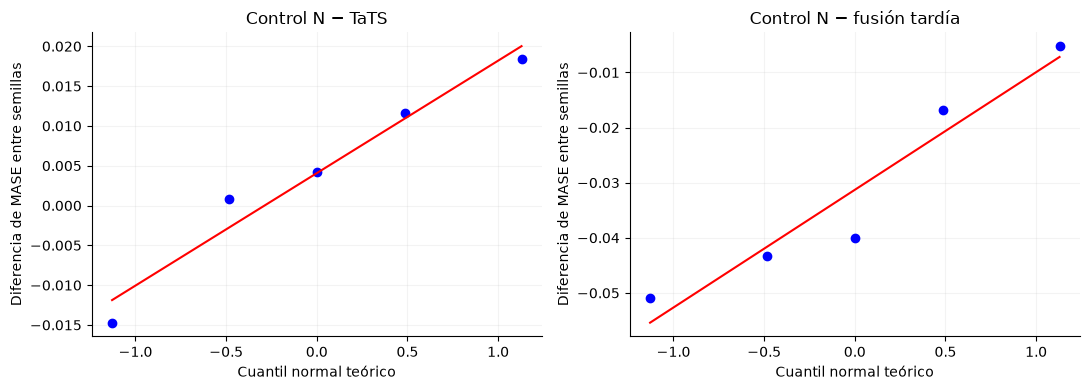

In [6]:
with np.load(RESULT/'perdidas_y_bootstrap.npz',allow_pickle=False) as z:
    matriz_semillas=z['semillas']; claves_semillas=z['nombres'].tolist()[:12]
fig, axes=plt.subplots(1,2,figsize=(11,4))
for ax,r in zip(axes,sel.itertuples()):
    d=matriz_semillas[:,claves_semillas.index(r.A)]-matriz_semillas[:,claves_semillas.index(r.B)]
    stats.probplot(d,dist='norm',plot=ax)
    ax.set_title('Control N − TaTS' if 'modelo6' in r.B else 'Control N − fusión tardía')
    ax.set_xlabel('Cuantil normal teórico');ax.set_ylabel('Diferencia de MASE entre semillas');ax.grid(alpha=.15)
fig.tight_layout();display(fig);plt.close(fig)


Cinco puntos permiten detectar desviaciones grandes, pero no acreditar normalidad. La t pareada se mantiene como sensibilidad; el bootstrap temporal no depende de seleccionar una prueba tras observar este gráfico.

## Friedman, post hoc y conjunto de confianza

Friedman utiliza cinco bloques de semillas y doce procedimientos. Es un análisis condicionado a esta serie, no una comparación sobre cinco datasets independientes. El post hoc Nemenyi emplea rangos medios y una distancia crítica de aproximadamente 7,45 posiciones, considerable por el pequeño número de bloques. Se conserva además Wilcoxon–Holm completo como alternativa post hoc.

Friedman: Q=51.553846; p=3.28358e-07
Sensibilidad por permutación de etiquetas dentro de semilla: p=9.999e-05
Levene centrado en mediana: p=0.313366


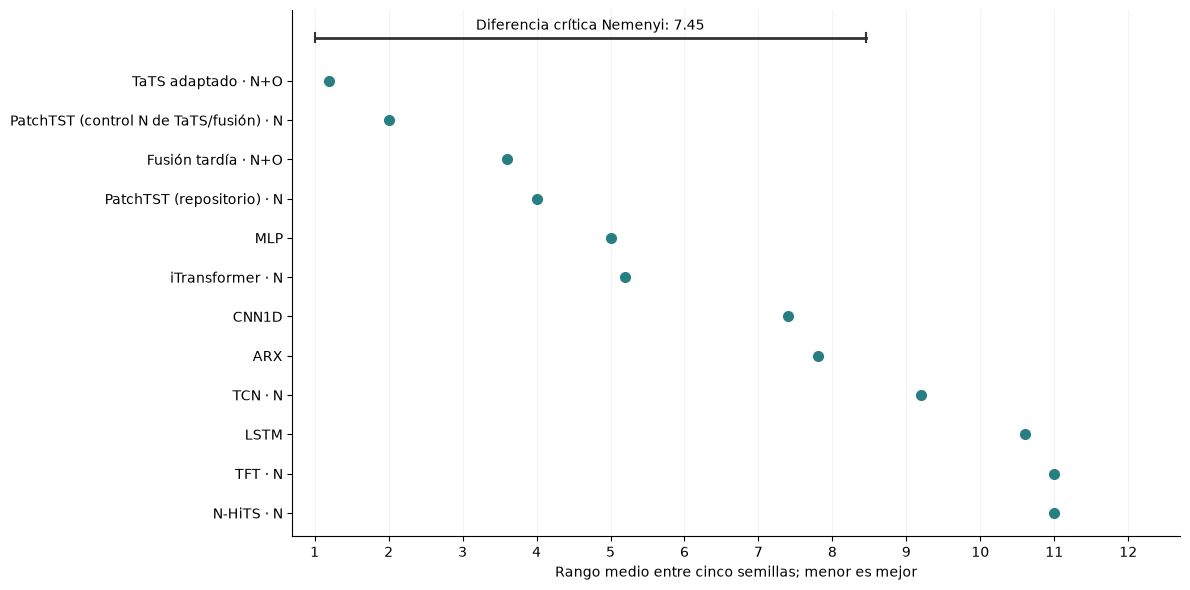

In [7]:
print(f"Friedman: Q={protocolo['friedman']:.6f}; p={protocolo['p_Friedman']:.6g}")
print(f"Sensibilidad por permutación de etiquetas dentro de semilla: p={protocolo['p_Friedman_permutacion']:.6g}")
print(f"Levene centrado en mediana: p={protocolo['p_Levene']:.6f}")
rangos = pd.read_csv(RESULT/'rangos.csv').sort_values('rango',ascending=False)
fig, ax = plt.subplots(figsize=(12,6))
ax.plot(rangos.rango,np.arange(len(rangos)),'o',color='#287f83',ms=7)
ax.set_yticks(np.arange(len(rangos)),rangos.modelo)
ax.set_xlim(.7,12.7);ax.set_xticks(np.arange(1,13));ax.set_xlabel('Rango medio entre cinco semillas; menor es mejor')
cd = protocolo['CD_Nemenyi'];yy=len(rangos)+.1
ax.plot([1,1+cd],[yy,yy],color='#333333',lw=2)
ax.plot([1,1],[yy-.12,yy+.12],color='#333333');ax.plot([1+cd,1+cd],[yy-.12,yy+.12],color='#333333')
ax.text(1+cd/2,yy+.2,f'Diferencia crítica Nemenyi: {cd:.2f}',ha='center')
ax.set_ylim(-.6,len(rangos)+.8);ax.grid(axis='x',alpha=.15)
fig.tight_layout();display(fig);plt.close(fig)


Friedman rechaza igualdad global de rangos, pero no afirma que todos los pares difieran. La distancia crítica exige separaciones grandes para rechazar con Nemenyi; una separación menor no demuestra equivalencia. Levene no rechaza heterogeneidad de varianzas al nivel 0,05, aunque tiene poca sensibilidad con cinco métricas por procedimiento y no justifica ignorar el emparejamiento.

El Model Confidence Set utiliza pérdidas diarias y un estadístico de rango studentizado con el mismo bootstrap circular. Su eliminación secuencial controla la búsqueda de un conjunto de procedimientos compatibles con mejor precisión al nivel del 10 %.

In [8]:
mcs = pd.read_csv(RESULT/'mcs.csv')
display(mcs.loc[mcs.retenido_90,['modelo','p_MCS']].rename(columns={'modelo':'Retenido en MCS 90 %','p_MCS':'p MCS'}).round(6))


,Retenido en MCS 90 %,p MCS
12,PatchTST (control N de TaTS/fusión) · N,0.435556
13,TaTS adaptado · N+O,1.000000


El MCS retiene TaTS con texto oficial y su control numérico. No identifica un ganador único entre ellos ni demuestra que el texto sea necesario. La interpretación corresponde a los procedimientos completos y a las pérdidas sobre este bloque retrospectivo; no acredita generalización a otras series o datasets.

## Error por horizonte

Se muestran los errores de cada hora para distinguir un buen promedio de una mejora distribuida a lo largo del día. El código conserva los 24 horizontes y los mismos orígenes para todos los procedimientos.

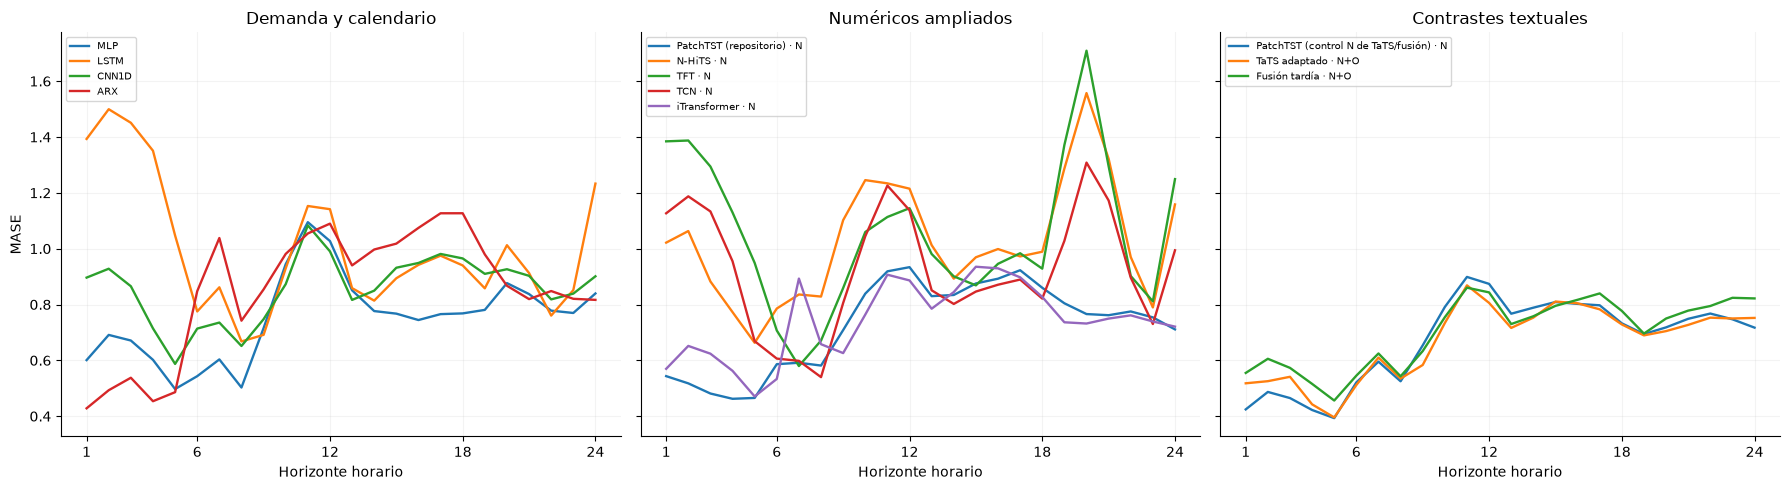

In [9]:
hor = pd.read_csv(RESULT/'resultados_horizonte.csv')
grupos = [(['mlp','lstm','cnn1d','arx_lineal'],'Demanda y calendario'),
          (['repo_patchtst_numerico_r1__N','repo_nhits_numerico_r1__N','adj_modelo3_20261115_0419__N','adj_modelo4_20261114_1224__N','adj_modelo5_20261114_1327__N'],'Numéricos ampliados'),
          (['adj_modelo6_20261112_1035__N','adj_modelo6_20261112_1035__N+O','adj_fusion_tardia_20261113_1728__N+O'],'Contrastes textuales')]
fig, axes = plt.subplots(1,3,figsize=(18,5),sharey=True)
for ax,(ks,titulo) in zip(axes,grupos):
    for k in ks:
        v=hor[hor.clave==k];ax.plot(v.horizonte,v.MASE,label=nombres[k],lw=1.7)
    ax.set_title(titulo);ax.set_xlabel('Horizonte horario');ax.set_xticks([1,6,12,18,24]);ax.grid(alpha=.15)
    ax.legend(fontsize=7,loc='upper left')
axes[0].set_ylabel('MASE');fig.tight_layout();display(fig);plt.close(fig)


El error depende de la hora: la diferencia entre familias no es una separación constante en todo el horizonte. Los perfiles de los contrastes textuales deben leerse junto con sus diferencias pareadas, no como 24 pruebas independientes sin corrección. Se conservan 48 contrastes DM–HLN de los dos aportes textuales, ajustados conjuntamente por Holm, en la tabla descargable.

## Curvas de aprendizaje

Cada panel conserva las cinco semillas: líneas de ajuste y de parada interna, y marcadores del mínimo restaurado de parada. Las familias base emplean MAE o Huber según su configuración; por ello las alturas no son comparables entre pérdidas diferentes.

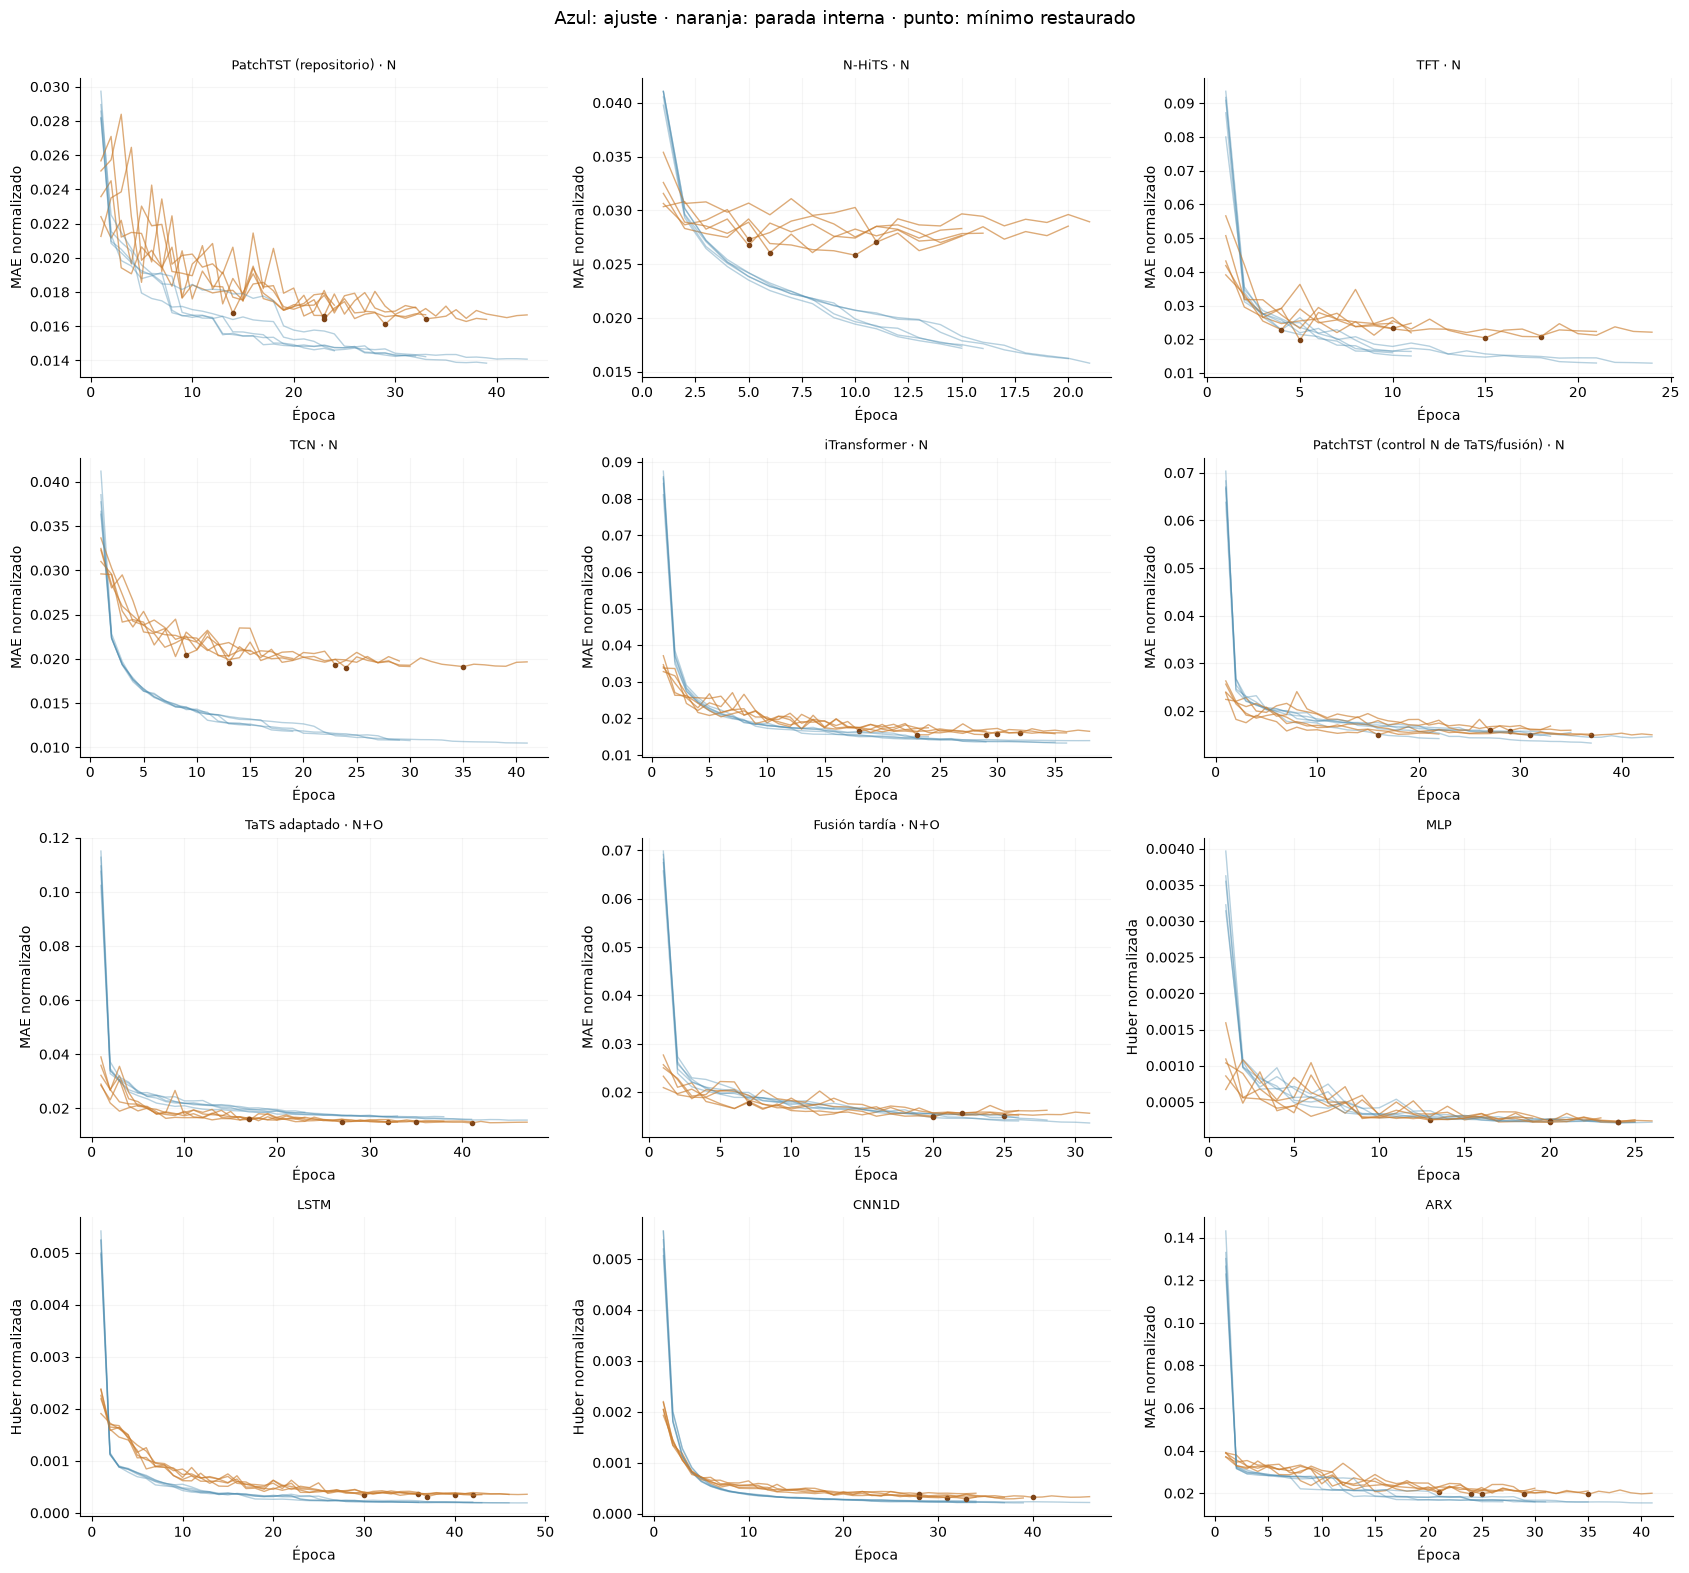

In [10]:
curvas = pd.read_csv(RESULT/'curvas_aprendizaje.csv')
ks = [k for k in benchmark.clave if k not in ['ingenuo_24h','ingenuo_168h']]
fig, axes = plt.subplots(4,3,figsize=(17,16))
for ax,k in zip(axes.flat,ks):
    c=curvas[curvas.clave==k]
    for s,g in c.groupby('semilla'):
        ax.plot(g.epoca,g.train_loss,color='#4a8baf',alpha=.4,lw=1)
        ax.plot(g.epoca,g.val_loss,color='#cb7e30',alpha=.65,lw=1)
        z=g.loc[g.val_loss.idxmin()];ax.plot(z.epoca,z.val_loss,'o',ms=3,color='#7e4417')
    ax.set_title(nombres[k],fontsize=9);ax.set_xlabel('Época');ax.set_ylabel(c.perdida.iloc[0]);ax.grid(alpha=.12)
fig.suptitle('Azul: ajuste · naranja: parada interna · punto: mínimo restaurado',fontsize=13)
fig.tight_layout(rect=[0,0,1,.98]);display(fig);plt.close(fig)


La parada ocurre antes del máximo de épocas en las realizaciones presentadas y restaura el mejor estado observado en la reserva interna. La separación ajuste–parada sugiere revisar generalización y estabilidad, pero no constituye por sí sola una prueba de sobreajuste. Los contrastes externos se basan en errores posteriores al ajuste; las curvas no se utilizan para volver a seleccionar modelos con la prueba.

## Diagnóstico de residuos y calibración

Para el diagnóstico se utiliza el residuo diario promedio de la predicción media de las cinco semillas. Este promedio se restringe al diagnóstico: no reemplaza la definición del benchmark. Se evalúan Ljung–Box a 7, 14 y 28 días, Ljung–Box de residuos cuadrados, ARCH-LM con 14 rezagos, BDS con dimensión 2 y radio 1,5 desviaciones, Jarque–Bera y calibración de Mincer–Zarnowitz. Cada columna de diagnósticos se ajusta por Holm entre los doce procedimientos.

In [11]:
diag = pd.read_csv(RESULT/'diagnostico_residuos.csv')
display(diag[['modelo','p_LB14_Holm','p_ARCH_Holm','p_BDS_Holm','p_Mincer_Zarnowitz_Holm']].rename(columns={
    'modelo':'Procedimiento','p_LB14_Holm':'Ljung–Box (14)','p_ARCH_Holm':'ARCH-LM','p_BDS_Holm':'BDS (m=2)',
    'p_Mincer_Zarnowitz_Holm':'Mincer–Zarnowitz'}).style.format({c:'{:.3g}' for c in ['Ljung–Box (14)','ARCH-LM','BDS (m=2)','Mincer–Zarnowitz']}))


,Procedimiento,Ljung–Box (14),ARCH-LM,BDS (m=2),Mincer–Zarnowitz
0,PatchTST (repositorio) · N,1.04e-08,0.000138,2.67e-08,5.44e-65
1,N-HiTS · N,6.16e-77,0.0249,2.48e-10,2.05e-85
2,TFT · N,5.46e-62,0.57,8.86e-27,7.83e-82
3,TCN · N,3.22e-09,0.57,1.55e-07,3.58e-27
4,iTransformer · N,3.28e-15,7.11e-05,0.000209,1.34e-40
5,PatchTST (control N de TaTS/fusión) · N,9.01e-14,0.183,3.92e-08,5.26e-23
6,TaTS adaptado · N+O,1.88e-30,0.0249,1.11e-13,6.08e-10
7,Fusión tardía · N+O,3.47e-19,0.0203,1.34e-09,1.73e-11
8,MLP,3.98e-08,0.0357,0.000209,3.11e-20
9,LSTM,5.04e-17,0.0907,1.44e-06,7.46e-40


Ljung–Box detecta dependencia residual y Mincer–Zarnowitz rechaza la calibración conjunta de intercepto cero y pendiente uno en los doce procedimientos. BDS también rechaza independencia; como ya existe autocorrelación, no debe interpretarse ese rechazo aisladamente como demostración de no linealidad. ARCH-LM rechaza ausencia de heterocedasticidad dinámica en parte de las familias, no en todas. La dependencia remanente justifica emplear inferencia temporal robusta y deja margen para mejorar la especificación.

Mincer–Zarnowitz se ajusta sobre demanda diaria media expresada en unidades q168 para evitar una matriz de restricciones mal condicionada; el contraste nulo sigue siendo intercepto cero y pendiente uno. La covarianza es HAC de 13 días. No se calcula PIT ni cobertura probabilística a partir del rango entre semillas, porque estos modelos entregan pronósticos puntuales.

## Discusión y alcance del Entregable 2

El mejor resultado disponible pertenece al conjunto TaTS–control numérico, no a un ganador estadístico único. Añadir texto oficial no acredita una mejora práctica del 3 % en TaTS y empeora la fusión tardía. La equivalencia temporal de TaTS con su control sugiere valorar el coste de codificación y parámetros adicionales antes de recomendar el componente textual. No demuestra que todo texto sea inútil: el resultado está limitado al corpus declarado, sus fechas, selección y mecanismos de fusión.

La comparación de coste debe utilizar parámetros, tiempos y dispositivos registrados; GPU AMD/ROCm y NVIDIA/CUDA no son condiciones idénticas. No se comparan tiempos de entrenamiento como si midieran exclusivamente eficiencia arquitectónica. Las curvas y diagnósticos muestran error remanente; no permiten estimar un ruido irreducible ni afirmar cercanía a un techo de desempeño.

Las pruebas incorporadas cubren la evaluación estadística posible con las predicciones recibidas. El E2 no queda completamente satisfecho: falta la evaluación de TGForecaster, una referencia ARIMA/ETS, presupuestos homogéneos, dimensionamiento suficiente de semillas, las búsquedas arquitectónicas exigibles de §14 y ablaciones/robustez controladas que no se reconstruyen con predicciones finales. Clark–West no se aplica automáticamente a MAE ni a estas redes anidadas no lineales; Giacomini–White requiere justificar su esquema de estimación e instrumentos. Estas omisiones no se reemplazan por p-valores de otra hipótesis.

La selección y exposición retrospectiva limitan la validez confirmatoria. Los IC temporales son condicionales a las cinco semillas; Friedman y Wilcoxon caracterizan incertidumbre de inicialización en esta serie, no generalización entre datasets. Las amenazas de disponibilidad textual, cambios de composición y revisiones de reanálisis se conservan en el diseño de datos.

## Tablas y reproducción

[Benchmark completo](_static/resultados/evaluacion_e2/benchmark.csv) · [91 comparaciones temporales](_static/resultados/evaluacion_e2/comparaciones_temporales.csv) · [Contrastes textuales](_static/resultados/evaluacion_e2/contrastes_texto.csv) · [66 comparaciones entre semillas](_static/resultados/evaluacion_e2/comparaciones_semillas.csv) · [Nemenyi](_static/resultados/evaluacion_e2/nemenyi.csv) · [MCS](_static/resultados/evaluacion_e2/mcs.csv) · [Diagnósticos](_static/resultados/evaluacion_e2/diagnostico_residuos.csv) · [Por horizonte](_static/resultados/evaluacion_e2/resultados_horizonte.csv) · [DM por horizonte](_static/resultados/evaluacion_e2/DM_por_horizonte_texto.csv) · [Sensibilidad de bloques](_static/resultados/evaluacion_e2/sensibilidad_bloques_texto.csv) · [Curvas](_static/resultados/evaluacion_e2/curvas_aprendizaje.csv) · [Protocolo](_static/resultados/evaluacion_e2/protocolo.json).

El siguiente código es el pipeline estadístico ejecutado. Carga predicciones conservadas, reconstruye referencias con disponibilidad, calcula pérdidas y aplica las pruebas descritas; no llama a entrenamiento ni genera nuevas predicciones de redes.

```{literalinclude} _static/codigo_e2/estadistica_e2.py
:language: python
:linenos:
```

La comparación por rangos se apoya en [Demšar (2006)](https://www.jmlr.org/papers/v7/demsar06a.html), adaptando su interpretación a semillas en una única serie. El MCS utiliza el estadístico de rango y bootstrap temporal descritos en la [documentación de referencia de MCS](https://arch.readthedocs.io/en/latest/multiple-comparison/generated/arch.bootstrap.MCS.html); el código visible conserva su implementación explícita.